# Mini Project — Build a RAG System for Your Own Data
### IT7075: Applied AI for Cybersecurity · Retrieval-Augmented Generation

The first half of this notebook is the lecture pipeline with five pieces left for you to write, one per
step of the RAG recipe you saw in class:

| | Step | You write |
|---|---|---|
| **TODO 1** | chunk the documents | 3 lines |
| **TODO 2** | embed and store them in ChromaDB | 2 lines |
| **TODO 3** | retrieve the closest chunks | 3 lines |
| **TODO 4** | augment the prompt with what you retrieved | 2 lines |
| **TODO 5** | measure whether the answer was actually found | 4 lines |

Everything else is already written. Each TODO is marked like this, so you can find them by
searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

The five TODOs are practice on the course documents. After them, from Part 6 onward, no code is
provided: you build a RAG for data you create yourself, run your own experiments, and write it up in a
report and a video. Read `MiniProject_RAG.md` for the deliverables and the rubric.

> **Runs offline.** No API key needed. The generate step uses one if you have it, and otherwise
> prints an offline answer so the pipeline still works end to end.

## Part 1 — Chunk the documents  ·  **TODO 1**

The first few lines import what you need and load the embedding model — nothing to change there.
Then comes your first piece of code.

You cannot embed a whole document as one vector — one vector cannot represent ten topics. So you
cut each document into overlapping chunks, exactly as in Lecture 2. The **overlap** keeps a
sentence that lands on a boundary from being lost to both chunks.

> **Expected output:** `ssrf.txt -> 11 chunks`, `cybersecurity_kb.md -> 11 chunks`, **22 total**.

In [10]:
%pip install -q chromadb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 102.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/1

In [11]:
import chromadb
print("ChromaDB installation successful!")

ChromaDB installation successful!


In [12]:
# If needed:  !pip install -q sentence-transformers chromadb pandas matplotlib openai
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Keep this notebook on the CPU. The model here is tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

from sentence_transformers import SentenceTransformer
import chromadb

# ---- the documents that came with the course -----------------------------
def kb_path(name):
    """The course files live in RAG/code/. Works from this folder or solutions/."""
    p = "../../code/" + name
    return p if os.path.exists(p) else "../../../code/" + name

COURSE_KB = [
    "/content/ssrf.txt",
    "/content/cybersecurity_kb.md"
]

# the question set for those documents (Part 5) sits next to this notebook
GOLDSET_FILE = ("baseline_goldset.json" if os.path.exists("baseline_goldset.json")
                else "../baseline_goldset.json")

# ---- ONE embedding model, used for BOTH the chunks and the questions -----
embedder = SentenceTransformer("all-MiniLM-L6-v2")     # 384 numbers per text, runs locally

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True).tolist()


###################  TODO 1 — cut a document into overlapping chunks  ###################
# WHAT: finish split_into_chunks() so it returns a list of text pieces.
#
# HOW (this is the Lecture 2 chunking cell):
#   * piece  = chunk_size characters of `text`, starting at `start`, with .strip()
#              applied so you don't keep leading/trailing whitespace
#   * append the piece to `pieces`, but ONLY if it is not an empty string
#   * move `start` forward by (chunk_size - overlap) -- NOT by chunk_size,
#     because the two chunks are supposed to share `overlap` characters
#
# WATCH OUT: if you move `start` forward by chunk_size you get no overlap at all;
#            if you forget to move it, the loop never ends.
################

def split_into_chunks(text, chunk_size=600, overlap=100):
    pieces = []
    start = 0
    while start < len(text):
        piece = text[start:start + chunk_size].strip()                                         # <<< 1 line
        if piece:                                             # <<< 1 line
            pieces.append(piece)
        start = start + (chunk_size - overlap)                                         # <<< 1 line
    return pieces


# ---- given: apply it to both course documents ---------------------------
def load_and_chunk(files, chunk_size=600, overlap=100):
    """Read every file, chunk it, and remember which file each chunk came from."""
    chunks, sources = [], []
    for path in files:
        text = open(path, encoding="utf-8").read()
        pieces = split_into_chunks(text, chunk_size, overlap)
        chunks += pieces
        sources += [os.path.basename(path)] * len(pieces)
        print("  %-24s -> %2d chunks" % (os.path.basename(path), len(pieces)))
    return chunks, sources

chunks, sources = load_and_chunk(COURSE_KB)
print("  TOTAL:", len(chunks), "chunks")
print("\nFirst chunk starts:", chunks[0][:70])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  ssrf.txt                 -> 11 chunks
  cybersecurity_kb.md      -> 11 chunks
  TOTAL: 22 chunks

First chunk starts: Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


## Part 2 — Embed and store in ChromaDB  ·  **TODO 2**

Now turn every chunk into a vector and put it in the vector database, as in Lecture 2. The
collection is created for you with `cosine` distance — Chroma's default is a different metric, and
every threshold in this notebook assumes cosine.

> **Expected output:** `Stored 22 chunks`.

In [13]:
client = chromadb.EphemeralClient()
_counter = [0]

def build_collection(chunks, sources):
    """Given: make a NEW empty collection using cosine distance, then fill it."""
    _counter[0] += 1                     # a fresh name each time, so re-running
    name = "kb_%d" % _counter[0]         # never mixes old chunks with new ones
    collection = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})

    ###################  TODO 2 — put the chunks in the database  ###################
    # WHAT: give collection.add() the two arguments it is still missing.
    #
    # HOW (the Lecture 2 "operate ChromaDB" cell):
    #   * embeddings = the vectors for `chunks`. Use the embed() helper from
    #     Part 1 -- the SAME model must embed the chunks and, later, the question,
    #     or the distances mean nothing.
    #   * metadatas  = one small dict per chunk recording where it came from:
    #                  [{"source": s} for s in sources]
    #                  This is what lets an answer cite a file.
    ################

    collection.add(ids=["c%d" % i for i in range(len(chunks))],
                   documents=chunks,
                   embeddings=embed(chunks),                                # <<< 1 line
                   metadatas=[{"source": s} for s in sources])                                 # <<< 1 line
    return collection


collection = build_collection(chunks, sources)
print("Stored", collection.count(), "chunks")

Stored 22 chunks


## Part 3 — Retrieve  ·  **TODO 3**

Embed the question with the same model, ask the database for the `k` closest chunks, and throw
away anything farther than `max_distance`.

That last step is the one people skip, and it matters: without it the database **always** returns
`k` chunks no matter how irrelevant, so your bot will happily answer a question your documents
never covered. An empty result is a *good* result — Part 4 turns it into "I don't know".

> **Expected output:** 4 hits for the SSRF question with distances around 0.36–0.43, and
> **0 hits** for "What is the capital of France?".

In [14]:
###################  TODO 3 — find the closest chunks  ###################
# WHAT: finish retrieve() so it returns a list of hits, closest first.
#       Each hit is a dict: {"text": ..., "distance": ..., "source": ...}
#
# HOW (the Lecture 3 retrieve cell):
#   * query the collection with the EMBEDDED question and n_results=k:
#         results = collection.query(query_embeddings=embed([question]), n_results=k)
#   * Chroma wraps its answer in a list (one entry per question, and we asked one),
#     so the pieces you want are:
#         results["documents"][0]   results["distances"][0]   results["metadatas"][0]
#   * keep a hit only when its distance <= max_distance
#
# REMEMBER: cosine distance, so SMALL = similar. 0.0 is identical, 1.0 is unrelated.
################

def retrieve(collection, question, k=4, max_distance=0.75):
    results = collection.query(
        query_embeddings=embed([question]),
        n_results=k
    )

    hits = []
    for doc, dist, meta in zip(
        results["documents"][0],
        results["distances"][0],
        results["metadatas"][0]
    ):
        if dist <= max_distance:
            hits.append({
                "text": doc,
                "distance": dist,
                "source": meta["source"]
            })
    return hits


# ---- given: try it on a question the documents answer, and one they don't
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?",
          "What is the capital of France?"]:
    found = retrieve(collection, q)
    print("Q:", q)
    print("   hits:", len(found))
    for h in found:
        print("     distance %.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                   h["text"][:60].replace("\n", " ")))
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved?
   hits: 4
     distance 0.356  [ssrf.txt]  ed, and if poorly handled, can perform specific injection at...
     distance 0.399  [ssrf.txt]  teract with the internal/external network or the machine its...
     distance 0.405  [ssrf.txt]  ed to perform an SSRF attack. Take a look at the XXE cheat s...
     distance 0.431  [ssrf.txt]  ill be based on the following information:  String containin...

Q: What is the capital of France?
   hits: 0



## Part 4 — Augment the prompt and generate  ·  **TODO 4**

Augmentation is just building a string: paste the retrieved chunks into the prompt and tell the
model to answer from them only. `generate()` and `ask()` are written for you.

> **Expected output:** the SSRF question comes back tagged `[RAG]`; the Log4Shell question comes
> back tagged `[LLM]` with no context — the honest refusal from Lecture 3.

In [15]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
    "Cite the source file for every claim, like [ssrf.txt]. If the answer is in the context, start "
    "your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
    "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)

###################  TODO 4 — build the context block  ###################
# WHAT: finish build_context() so it turns a list of hits into ONE string.
#
# Format each hit like this, so the answer can be traced back to a file:
#
#     [1] (source: ssrf.txt)
#     <the chunk text>
#
#     [2] (source: cybersecurity_kb.md)
#     <the chunk text>
#
# HOW:
#   * loop over hits with  enumerate(hits, start=1)  so the numbering starts at 1
#   * build each block as  "[%d] (source: %s)\n%s" % (i, h["source"], h["text"])
#   * join the blocks with a BLANK LINE between them:  "\n\n".join(blocks)
#
# IMPORTANT: return "" when hits is empty. That empty string is what triggers the
#            [LLM] refusal path below -- do not return "no results" text instead.
################

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, h in enumerate(hits, start=1):
        blocks.append(
            "[%d] (source: %s)\n%s" %
            (i, h["source"], h["text"])
        )
    return "\n\n".join(blocks)                                                            # <<< 1 line


# ---- given: generate an answer, then the whole pipeline in one function --
_USE_API = [True]      # set to False after one failure, so we don't retry a dead key

def generate(system, user):
    """Uses an LLM if one is available; otherwise quotes the context so this runs offline.

    The API call is guarded: if your key is missing, expired, or out of credit, the
    notebook prints one short note and keeps going in offline mode. Retrieval,
    scoring, and the whole tuning experiment do not need an LLM at all.
    """
    if os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        try:
            from openai import OpenAI
            r = OpenAI().chat.completions.create(
                model="gpt-4o-mini", temperature=0,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
            return r.choices[0].message.content
        except Exception as e:
            _USE_API[0] = False
            print("   (LLM unavailable - %s. Switching to offline mode for the rest of the"
                  " notebook; nothing in this project needs an LLM.)" % type(e).__name__)

    context = system.split("# Context\n", 1)[-1]
    if context.strip() == "" or context.strip() == "(nothing found)":
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]


def ask(collection, question, k=4, max_distance=0.75, show=True):
    """The complete RAG pipeline: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    system = SYSTEM.format(context=context if context else "(nothing found)")
    answer = generate(system, question)
    if show:
        print("Q:", question)
        print("   grounded?", "YES, %d chunk(s)" % len(hits) if hits else "NO, nothing retrieved")
        print("   answer:", answer[:300].replace("\n", "\n           "), "\n")
    return {"hits": hits, "answer": answer}


_ = ask(collection, "What are the two basic cases in which SSRF can happen?")
_ = ask(collection, "What CVSS score did Log4Shell receive?")     # not in the documents

Q: What are the two basic cases in which SSRF can happen?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: ssrf.txt)
           ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE.
           Cases
           Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
           
            

Q: What CVSS score did Log4Shell receive?
   grounded? NO, nothing retrieved
   answer: [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 5 — Measure it  ·  **TODO 5**

To say one setting is better than another you need a number. `baseline_goldset.json` has **8
questions** about the course documents: **6 the documents answer** (each with the exact `evidence`
wording that proves it) and **2 they do not**.

Two counts, and that is all:

- **found** — of the 6 answerable questions, how many retrieved a chunk containing the evidence?
- **refused** — of the 2 unanswerable ones, how many correctly retrieved *nothing*?

> **Expected output at the Lecture 3 settings (k=4, threshold 0.75): found 6/6, refused 2/2.**

In [16]:
GOLDSET_FILE = "/content/baseline_goldset.json"

GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
print("Loaded", len(GOLDSET), "questions\n")

###################  TODO 5 — score one configuration  ###################
# WHAT: finish score() so it counts `found` and `refused`.
#
# For each question q in the gold set, retrieve() is already called for you.
# Then:
#   * if q["answerable"] is True:
#       - the question counts as FOUND when ANY retrieved hit contains ANY of the
#         phrases in q["evidence"]. Compare in lower case, because the documents
#         are not consistently capitalised:
#             phrase.lower() in hit["text"].lower()
#       - a small helper, found_evidence(hits, q["evidence"]), is started for you
#   * if q["answerable"] is False:
#       - it counts as REFUSED when len(hits) == 0 -- nothing was retrieved
#
# WHY only these two numbers: `found` tells you whether the right text reached the
# model, and `refused` tells you whether the bot keeps quiet when it should. A
# setting that improves one while wrecking the other is not an improvement.
################

def found_evidence(hits, evidence):
    for h in hits:
        for phrase in evidence:
            if phrase.lower() in h["text"].lower():
                return True
    return False


def score(collection, goldset, k=4, max_distance=0.75):
    found, refused = 0, 0
    for q in goldset:
        hits = retrieve(collection, q["question"], k, max_distance)
        if q["answerable"]:
            if found_evidence(hits, q["evidence"]):
                found += 1
        else:
            if len(hits) == 0:
                refused += 1
    return found, refused


n_answerable = sum(q["answerable"] for q in GOLDSET)
n_unanswerable = len(GOLDSET) - n_answerable

found, refused = score(collection, GOLDSET)
print("found   %d/%d answerable questions" % (found, n_answerable))
print("refused %d/%d unanswerable questions" % (refused, n_unanswerable))

Loaded 8 questions

found   6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6: from here on, the code is yours

Everything above ran on the course documents, and it was practice: the same pipeline you saw in the
lectures, one piece at a time. The rest of this notebook is a RAG for your own data, and no code is
provided for it. Reuse anything you wrote in Parts 1 to 5, adapt code from the lecture notebooks, or
write something different. What matters is that it works on your data and that you can explain it.

Add cells below that do all of the following:

1. Load your documents from `my_kb/` and report how many documents and how many characters you have.
2. Load your questions from `goldset.json`, and check that every evidence phrase really appears in your
   documents exactly as written. If one does not, your own results will report a miss that is not real.
3. Chunk, embed, and store your documents.
4. Answer your questions and print the transcript, including at least one question your documents cannot
   answer, so that the refusal is visible.
5. Run your experiments. Change one setting at a time, such as chunk size, the number of chunks
   retrieved, or the distance threshold, score each configuration against your gold set, collect the
   results in a table, and save it as `results.csv`.
6. Draw at least one chart from your results and save it as a `.png`.

The cells below are empty on purpose. Add as many more as you need.

> When you are finished, run the whole notebook top to bottom and save it with the outputs showing,
> then commit it to your private GitHub repository along with `my_kb/`, `goldset.json`, `results.csv`,
> and your chart. See `MiniProject_RAG.md` section 7.1 for the folder structure.

In [17]:
###################  YOUR DATA — load and check  ###################
# Load your documents from my_kb/ and your questions from goldset.json.
# Report the document count and total characters, and check that every
# evidence phrase appears in your documents word-for-word.
################

import os

os.makedirs("/content/my_kb", exist_ok=True)

print("Created folder: /content/my_kb")

Created folder: /content/my_kb


In [18]:
from pathlib import Path

document = """# Password Fundamentals

## Why Password Security Matters

Passwords protect access to email, banking, university systems,
and other online accounts. Weak or reused passwords increase
the risk of unauthorized access.

## Creating Strong Passwords

A strong password should be long, unique, and difficult to guess.
NIST recommends passwords of at least 15 characters when a
password is used as the only authentication factor.

Long passphrases made from unrelated words can be easier to
remember than short, complicated passwords.

## Password Reuse

Using the same password for multiple accounts is dangerous.
If one website suffers a data breach, attackers may try the
stolen password on other services.

Every important account should have a unique password.

## Common Password Mistakes

Avoid using names, birthdays, common words, or predictable
patterns such as Password123.

Do not share passwords through email or text messages.
Do not store passwords in unprotected documents.

## Key Recommendations

Use long and unique passwords.
Use a reputable password manager to generate and store passwords.
Enable multi-factor authentication when available.
Change a password promptly if it is compromised.
"""

Path("/content/my_kb/01_password_fundamentals.md").write_text(
    document, encoding="utf-8"
)

print("Created: 01_password_fundamentals.md")
print("Characters:", len(document))

Created: 01_password_fundamentals.md
Characters: 1207


In [19]:
from pathlib import Path

Path("/content/my_kb").mkdir(parents=True, exist_ok=True)

print("Created folder: /content/my_kb")

Created folder: /content/my_kb


In [20]:
from pathlib import Path

document = """# Password Managers

## What Is a Password Manager?

A password manager is software that generates, stores, and
retrieves passwords for online accounts. It helps users maintain
a different strong password for each website without needing
to memorize every password.

## How Password Managers Work

Most password managers store credentials in an encrypted vault.
Users unlock the vault with a master password or another
supported authentication method.

A password manager can automatically generate long, random
passwords and fill login forms on recognized websites.

## Benefits

Password managers reduce password reuse across accounts.
They make it easier to use long and unique passwords.
Some password managers can identify weak, reused, or
compromised passwords.

## Master Password Security

The master password protects access to the password vault.
It should be strong, unique, and never reused for another
account.

Multi-factor authentication should be enabled for the
password manager account whenever supported.

## Limitations and Risks

A password manager does not eliminate every security risk.
Phishing, malware, compromised devices, and weak master
passwords can still threaten account security.

Users should choose reputable password managers, keep
software updated, and understand the recovery options
available if access to the vault is lost.

## Best Practices

Use a unique master password.
Enable multi-factor authentication.
Generate different passwords for different accounts.
Review security alerts about compromised credentials.
Avoid storing the master password in an unprotected file.
"""

Path("/content/my_kb/02_password_managers.md").write_text(
    document, encoding="utf-8"
)

print("Created: 02_password_managers.md")
print("Characters:", len(document))

Created: 02_password_managers.md
Characters: 1615


In [21]:
from pathlib import Path

document = """# Multi-Factor Authentication (MFA)

## What Is MFA?

Multi-factor authentication is a security method that requires
users to provide two or more different types of authentication
factors before accessing an account.

MFA provides an additional layer of protection beyond a password.

## Three Authentication Factor Categories

Authentication factors are generally divided into three categories:

1. Something you know, such as a password or PIN.
2. Something you have, such as a security key or authenticator device.
3. Something you are, such as a fingerprint or facial recognition.

Using two passwords does not qualify as multi-factor authentication
because both belong to the same factor category.

## Common MFA Methods

Authenticator applications can generate time-based one-time
passwords (TOTP) that expire after a short period.

Hardware security keys can use FIDO2 or WebAuthn authentication
to provide phishing-resistant protection.

SMS verification codes are widely available but can be vulnerable
to SIM-swapping attacks and phishing.

## Why MFA Matters

If an attacker steals a user's password, MFA can prevent the
attacker from signing in without the additional authentication
factor.

However, not all MFA methods provide equal protection.

## MFA Limitations

Attackers may trick users into revealing one-time codes through
phishing websites.

Repeated authentication prompts may lead to MFA fatigue,
where a user accidentally approves a fraudulent login attempt.

Phishing-resistant authentication methods are preferable
for accounts containing sensitive information.

## MFA Best Practices

Enable MFA for email, financial, and other important accounts.
Prefer passkeys or hardware security keys when supported.
Never share verification codes with another person.
Do not approve unexpected authentication requests.
Store backup recovery codes securely.
"""

Path("/content/my_kb/03_mfa.md").write_text(
    document, encoding="utf-8"
)

print("Created: 03_mfa.md")
print("Characters:", len(document))

Created: 03_mfa.md
Characters: 1875


In [22]:
from pathlib import Path

document = """# Phishing and Password Attacks

## What Is Phishing?

Phishing is a social engineering attack in which an attacker
pretends to be a trusted organization or person to steal
sensitive information such as passwords and verification codes.

Phishing messages may arrive through email, text messages,
social media, or fraudulent websites.

## How Credential Phishing Works

An attacker may send a message claiming that an account has
been suspended or requires immediate verification.

The message directs the victim to a fake login page that
resembles a legitimate website.

When the victim enters a username and password, the attacker
can capture the credentials and attempt to access the account.

## Credential Stuffing

Credential stuffing is an attack that uses stolen username
and password combinations from one data breach to attempt
logins on other websites.

Credential stuffing is effective when users reuse passwords
across multiple accounts.

Using a unique password for every account reduces the risk
that one compromised password will expose other accounts.

## Password Spraying

Password spraying involves trying a small number of common
passwords against many different accounts.

Attackers may use this method to avoid triggering account
lockouts caused by repeated failed attempts on one account.

## Brute-Force Attacks

A brute-force attack systematically tries password combinations
until a correct password is discovered.

Long and unpredictable passwords increase the difficulty
of brute-force guessing.

Rate limiting and additional authentication controls can
help defend online login systems.

## Recognizing Phishing Attempts

Be cautious of unexpected messages requesting passwords,
verification codes, or urgent account actions.

Inspect website addresses carefully before entering credentials.

Do not assume a message is legitimate simply because it
contains a familiar company logo or sender name.

## Preventing Password Attacks

Use a unique password for every important account.
Enable multi-factor authentication whenever possible.
Prefer phishing-resistant authentication methods.
Avoid clicking suspicious login links.
Use trusted websites or applications to access accounts.
Report suspected phishing attempts to the appropriate
security or IT department.
"""

Path("/content/my_kb/04_phishing_and_attacks.md").write_text(
    document, encoding="utf-8"
)

print("Created: 04_phishing_and_attacks.md")
print("Characters:", len(document))

Created: 04_phishing_and_attacks.md
Characters: 2293


In [23]:
from pathlib import Path

document = """# Responding to Password Breaches

## What Is a Password Breach?

A password breach occurs when an unauthorized person obtains
passwords or other authentication credentials.

Credentials may be exposed through compromised websites,
phishing attacks, malware, or insecure storage systems.

A data breach does not always mean that every password was
exposed. Users should review official breach notifications
to understand which information was affected.

## Warning Signs of Account Compromise

Unexpected password reset emails may indicate that someone
is attempting to access an account.

Other warning signs include unfamiliar login locations,
unrecognized devices, unauthorized transactions, and changes
to account recovery settings.

A warning sign does not always prove that an account has
been compromised, but it should be investigated.

## Immediate Response

If a password is compromised, change it immediately using
the official website or application.

Choose a new, strong, unique password that has not been
used for another account.

If the same password was reused elsewhere, change those
passwords as well.

## Securing the Account

Review recent account activity and active login sessions.

Sign out of unfamiliar devices and revoke suspicious sessions
when the service provides those options.

Check whether the attacker changed recovery email addresses,
phone numbers, or multi-factor authentication settings.

Enable multi-factor authentication if it is not already active.

## Protecting the Device

If malware may have stolen credentials, scan the device using
trusted security software and install available updates.

A compromised device may capture a new password, so the
device should be secured before entering replacement credentials.

When possible, use a known-clean device to recover the account.

## Reporting the Incident

For a university or workplace account, contact the
organization's IT security team promptly.

For financial accounts, contact the institution if
unauthorized transactions or suspicious activity occurred.

Follow the organization's incident response procedures
and preserve relevant notifications or records.

## Recovery and Prevention

Monitor the affected account for additional suspicious activity.

Review connected applications and revoke access that is
no longer needed.

Use a password manager to generate unique passwords.

Enable phishing-resistant MFA when available.

Keep recovery information current and store backup codes securely.

## Key Response Checklist

1. Verify the breach notification through an official source.
2. Secure the affected device if compromise is suspected.
3. Change the compromised password.
4. Replace reused passwords on other accounts.
5. Review sessions, recovery settings, and account activity.
6. Enable or strengthen multi-factor authentication.
7. Report suspicious activity when appropriate.
8. Continue monitoring the affected account.
"""

Path("/content/my_kb/05_breach_response.md").write_text(
    document, encoding="utf-8"
)

print("Created: 05_breach_response.md")
print("Characters:", len(document))

Created: 05_breach_response.md
Characters: 2939


In [24]:
from pathlib import Path

sources = """# Knowledge Base Sources

Project: Password Security — A RAG-Based Question Answering System

## Document Origins

1. 01_password_fundamentals.md
   Original educational summary about strong passwords,
   password reuse, and password security practices.

2. 02_password_managers.md
   Original educational summary about password managers,
   encrypted vaults, master passwords, and limitations.

3. 03_mfa.md
   Original educational summary about multi-factor
   authentication, authentication factors, and MFA risks.

4. 04_phishing_and_attacks.md
   Original educational summary about phishing,
   credential stuffing, password spraying, and brute-force attacks.

5. 05_breach_response.md
   Original educational summary about recognizing and
   responding to compromised credentials.

## Authorship

These five documents were prepared for the IT7075 RAG
mini-project with assistance from ChatGPT. They are
educational summaries rather than verbatim reproductions
of external documents.

## Reference Organizations

NIST: https://www.nist.gov/
CISA: https://www.cisa.gov/
OWASP: https://owasp.org/

These organizations provide general background resources
on authentication and cybersecurity. The URLs are not
citations to specific passages in the five documents.
"""

Path("/content/my_kb/SOURCES.md").write_text(
    sources, encoding="utf-8"
)

print("Created: SOURCES.md")

Created: SOURCES.md


In [25]:
import json
from pathlib import Path

goldset = {
    "questions": [
        {
            "question": "Why is password reuse dangerous?",
            "answerable": True,
            "evidence": [
                "Every important account should have a unique password."
            ]
        },
        {
            "question": "What does a password manager help users do?",
            "answerable": True,
            "evidence": [
                "Password managers reduce password reuse across accounts."
            ]
        },
        {
            "question": "What are the three authentication factor categories?",
            "answerable": True,
            "evidence": [
                "Something you know, such as a password or PIN.",
                "Something you have, such as a security key or authenticator device.",
                "Something you are, such as a fingerprint or facial recognition."
            ]
        },
        {
            "question": "Why can SMS verification codes be insecure?",
            "answerable": True,
            "evidence": [
                "to SIM-swapping attacks and phishing."
            ]
        },
        {
            "question": "What is credential stuffing?",
            "answerable": True,
            "evidence": [
                "Credential stuffing is an attack that uses stolen username"
            ]
        },
        {
            "question": "What should a user do after a password is compromised?",
            "answerable": True,
            "evidence": [
                "change it immediately using",
                "the official website or application."
            ]
        },
        {
            "question": "Who invented the first computer password in 1961?",
            "answerable": False,
            "evidence": []
        },
        {
            "question": "What is the exact number of password breaches worldwide in 2025?",
            "answerable": False,
            "evidence": []
        }
    ]
}

path = Path("/content/goldset.json")
path.write_text(
    json.dumps(goldset, indent=2),
    encoding="utf-8"
)

print("Created:", path.name)
print("Total questions:", len(goldset["questions"]))
print("Answerable:", sum(q["answerable"] for q in goldset["questions"]))
print("Unanswerable:", sum(not q["answerable"] for q in goldset["questions"]))

Created: goldset.json
Total questions: 8
Answerable: 6
Unanswerable: 2


In [26]:
import json
from pathlib import Path

kb_folder = Path("/content/my_kb")

documents = "\n".join(
    file.read_text(encoding="utf-8")
    for file in kb_folder.glob("*.md")
    if file.name != "SOURCES.md"
)

goldset = json.loads(
    Path("/content/goldset.json").read_text(encoding="utf-8")
)

for i, item in enumerate(goldset["questions"], start=1):
    if not item["answerable"]:
        print(f"Q{i}: UNANSWERABLE")
        continue

    for evidence in item["evidence"]:
        found = evidence in documents
        status = "PASS" if found else "FAIL"
        print(f"Q{i}: {status} | {evidence}")

Q1: PASS | Every important account should have a unique password.
Q2: PASS | Password managers reduce password reuse across accounts.
Q3: PASS | Something you know, such as a password or PIN.
Q3: PASS | Something you have, such as a security key or authenticator device.
Q3: PASS | Something you are, such as a fingerprint or facial recognition.
Q4: PASS | to SIM-swapping attacks and phishing.
Q5: PASS | Credential stuffing is an attack that uses stolen username
Q6: PASS | change it immediately using
Q6: PASS | the official website or application.
Q7: UNANSWERABLE
Q8: UNANSWERABLE


In [27]:
from pathlib import Path

kb_dir = Path("/content/my_kb")

my_documents = []

for file in sorted(kb_dir.glob("*.md")):
    if file.name == "SOURCES.md":
        continue

    text = file.read_text(encoding="utf-8")

    my_documents.append({
        "source": file.name,
        "text": text
    })

    print(f"Loaded: {file.name} ({len(text)} characters)")

print("\nTotal documents:", len(my_documents))
print("Total characters:", sum(len(doc["text"]) for doc in my_documents))

Loaded: 01_password_fundamentals.md (1207 characters)
Loaded: 02_password_managers.md (1615 characters)
Loaded: 03_mfa.md (1875 characters)
Loaded: 04_phishing_and_attacks.md (2293 characters)
Loaded: 05_breach_response.md (2939 characters)

Total documents: 5
Total characters: 9929


In [28]:
# Step 11: Split our documents into chunks

def split_into_chunks(text, chunk_size=500, overlap=100):
    chunks = []

    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))

        chunk = text[start:end]
        chunks.append(chunk)

        if end == len(text):
            break

        start = end - overlap

    return chunks


my_chunks = []
my_sources = []

for doc in my_documents:
    chunks = split_into_chunks(
        doc["text"],
        chunk_size=500,
        overlap=100
    )

    for chunk in chunks:
        my_chunks.append(chunk)
        my_sources.append(doc["source"])

    print(f"{doc['source']}: {len(chunks)} chunks")

print("\nTotal chunks:", len(my_chunks))
print("First chunk preview:")
print(my_chunks[0][:300])

01_password_fundamentals.md: 3 chunks
02_password_managers.md: 4 chunks
03_mfa.md: 5 chunks
04_phishing_and_attacks.md: 6 chunks
05_breach_response.md: 8 chunks

Total chunks: 26
First chunk preview:
# Password Fundamentals

## Why Password Security Matters

Passwords protect access to email, banking, university systems,
and other online accounts. Weak or reused passwords increase
the risk of unauthorized access.

## Creating Strong Passwords

A strong password should be long, unique, and diffic


### Build your RAG and ask your questions

In [29]:
###################  YOUR RAG — build and ask  ###################
# Chunk, embed, and store your documents, then answer your own questions.
# Print the transcript, including a question your documents cannot answer.
################

import chromadb

# Create an in-memory ChromaDB database
my_client = chromadb.Client()

# Create a collection for our password security documents
my_collection = my_client.get_or_create_collection(
    name="password_security_kb"
)

# Clear existing records if this cell is run again
existing = my_collection.get()

if existing["ids"]:
    my_collection.delete(ids=existing["ids"])

# Store all chunks with their source filenames
my_collection.add(
    ids=[f"password_chunk_{i}" for i in range(len(my_chunks))],
    documents=my_chunks,
    metadatas=[
        {"source": source}
        for source in my_sources
    ]
)

print("Stored chunks:", my_collection.count())

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:02<00:00, 29.8MiB/s]


Stored chunks: 26


In [30]:
# Step 13: Retrieve relevant chunks from ChromaDB

def retrieve_password_info(question, k=3, max_distance=0.8):

    results = my_collection.query(
        query_texts=[question],
        n_results=k
    )

    retrieved = []

    for text, distance, metadata in zip(
        results["documents"][0],
        results["distances"][0],
        results["metadatas"][0]
    ):
        if distance <= max_distance:
            retrieved.append({
                "text": text,
                "distance": distance,
                "source": metadata["source"]
            })

    return retrieved


# Test retrieval
question = "Why is password reuse dangerous?"

hits = retrieve_password_info(question)

print("Question:", question)
print("Retrieved chunks:", len(hits))

for i, hit in enumerate(hits, start=1):
    print(f"\n--- Result {i} ---")
    print("Source:", hit["source"])
    print("Distance:", round(hit["distance"], 3))
    print("Text:", hit["text"][:300])

Question: Why is password reuse dangerous?
Retrieved chunks: 2

--- Result 1 ---
Source: 04_phishing_and_attacks.md
Distance: 0.696
Text: tions from one data breach to attempt
logins on other websites.

Credential stuffing is effective when users reuse passwords
across multiple accounts.

Using a unique password for every account reduces the risk
that one compromised password will expose other accounts.

## Password Spraying

Password

--- Result 2 ---
Source: 01_password_fundamentals.md
Distance: 0.7
Text: y authentication factor.

Long passphrases made from unrelated words can be easier to
remember than short, complicated passwords.

## Password Reuse

Using the same password for multiple accounts is dangerous.
If one website suffers a data breach, attackers may try the
stolen password on other servi


In [31]:
# Step 14: Generate a grounded response from retrieved evidence

def ask_password_rag(question, k=3, max_distance=0.8):

    hits = retrieve_password_info(
        question,
        k=k,
        max_distance=max_distance
    )

    if len(hits) == 0:
        return {
            "answer": "[REFUSED] I don't know based on the provided documents.",
            "hits": []
        }

    best_hit = hits[0]

    answer = (
        "[RAG] Retrieved evidence:\n"
        + best_hit["text"].strip()
        + "\n\nSource: "
        + best_hit["source"]
    )

    return {
        "answer": answer,
        "hits": hits
    }


# Test with an answerable question
question = "Why is password reuse dangerous?"

result = ask_password_rag(question)

print("Question:", question)
print()
print(result["answer"])

Question: Why is password reuse dangerous?

[RAG] Retrieved evidence:
tions from one data breach to attempt
logins on other websites.

Credential stuffing is effective when users reuse passwords
across multiple accounts.

Using a unique password for every account reduces the risk
that one compromised password will expose other accounts.

## Password Spraying

Password spraying involves trying a small number of common
passwords against many different accounts.

Attackers may use this method to avoid triggering account
lockouts caused by repeated failed attempts on

Source: 04_phishing_and_attacks.md


In [32]:
# Step 15: Test an unanswerable question

question = "What is the capital of France?"

result = ask_password_rag(
    question,
    k=3,
    max_distance=0.8
)

print("Question:", question)
print("Retrieved chunks:", len(result["hits"]))
print("Answer:", result["answer"])

for hit in result["hits"]:
    print(
        "Source:", hit["source"],
        "| Distance:", round(hit["distance"], 3)
    )

Question: What is the capital of France?
Retrieved chunks: 0
Answer: [REFUSED] I don't know based on the provided documents.


### Run your experiments and collect the results

In [33]:
###################  YOUR EXPERIMENTS  ###################
# Change one setting at a time, score each configuration against your gold
# set, collect the rows into a table, and save it as results.csv.
################# Step 16: Evaluate all 8 goldset questions

import json
from pathlib import Path

goldset = json.loads(
    Path("/content/goldset.json").read_text(encoding="utf-8")
)

found = 0
refused = 0

for i, item in enumerate(goldset["questions"], start=1):

    question = item["question"]
    answerable = item["answerable"]

    result = ask_password_rag(
        question,
        k=3,
        max_distance=0.8
    )

    has_hits = len(result["hits"]) > 0

    if answerable and has_hits:
        found += 1
        status = "PASS"

    elif not answerable and not has_hits:
        refused += 1
        status = "PASS"

    else:
        status = "FAIL"

    print(f"Q{i}: {status}")
    print("Question:", question)
    print("Expected:", "ANSWER" if answerable else "REFUSE")
    print("Actual:", "ANSWER" if has_hits else "REFUSE")
    print()

print("Found:", found, "/ 6")
print("Refused:", refused, "/ 2")

Q1: PASS
Question: Why is password reuse dangerous?
Expected: ANSWER
Actual: ANSWER

Q2: PASS
Question: What does a password manager help users do?
Expected: ANSWER
Actual: ANSWER

Q3: PASS
Question: What are the three authentication factor categories?
Expected: ANSWER
Actual: ANSWER

Q4: FAIL
Question: Why can SMS verification codes be insecure?
Expected: ANSWER
Actual: REFUSE

Q5: PASS
Question: What is credential stuffing?
Expected: ANSWER
Actual: ANSWER

Q6: PASS
Question: What should a user do after a password is compromised?
Expected: ANSWER
Actual: ANSWER

Q7: PASS
Question: Who invented the first computer password in 1961?
Expected: REFUSE
Actual: REFUSE

Q8: PASS
Question: What is the exact number of password breaches worldwide in 2025?
Expected: REFUSE
Actual: REFUSE

Found: 5 / 6
Refused: 2 / 2


In [34]:
# Step 17: Investigate the failed question (Q4)

question = "Why can SMS verification codes be insecure?"

results = my_collection.query(
    query_texts=[question],
    n_results=3
)

print("Question:", question)

for i, (text, distance, metadata) in enumerate(zip(
    results["documents"][0],
    results["distances"][0],
    results["metadatas"][0]
), start=1):

    print(f"\n--- Candidate {i} ---")
    print("Source:", metadata["source"])
    print("Distance:", round(distance, 3))
    print("Passes current threshold:", distance <= 0.8)
    print("Text:", text[:500])

Question: Why can SMS verification codes be insecure?

--- Candidate 1 ---
Source: 03_mfa.md
Distance: 0.873
Passes current threshold: False
Text: TP) that expire after a short period.

Hardware security keys can use FIDO2 or WebAuthn authentication
to provide phishing-resistant protection.

SMS verification codes are widely available but can be vulnerable
to SIM-swapping attacks and phishing.

## Why MFA Matters

If an attacker steals a user's password, MFA can prevent the
attacker from signing in without the additional authentication
factor.

However, not all MFA methods provide equal protection.

## MFA Limitations

Attackers may trick 

--- Candidate 2 ---
Source: 03_mfa.md
Distance: 1.08
Passes current threshold: False
Text: t Practices

Enable MFA for email, financial, and other important accounts.
Prefer passkeys or hardware security keys when supported.
Never share verification codes with another person.
Do not approve unexpected authentication requests.
Store backup recovery c

In [35]:
# Step 18: Experiment with distance thresholds

thresholds = [0.7, 0.8, 0.9, 1.0]

experiment_results = []

for threshold in thresholds:

    found = 0
    refused = 0

    for item in goldset["questions"]:

        hits = retrieve_password_info(
            item["question"],
            k=3,
            max_distance=threshold
        )

        if item["answerable"] and len(hits) > 0:
            found += 1

        if not item["answerable"] and len(hits) == 0:
            refused += 1

    experiment_results.append({
        "max_distance": threshold,
        "found": found,
        "refused": refused
    })

    print(
        f"Threshold: {threshold:.1f} | "
        f"Found: {found}/6 | "
        f"Refused: {refused}/2"
    )

Threshold: 0.7 | Found: 5/6 | Refused: 2/2
Threshold: 0.8 | Found: 5/6 | Refused: 2/2
Threshold: 0.9 | Found: 6/6 | Refused: 2/2
Threshold: 1.0 | Found: 6/6 | Refused: 1/2


In [36]:
# Step 19: Experiment with retrieval k

k_values = [1, 2, 3, 5, 8]

k_results = []

for k in k_values:

    found = 0
    refused = 0

    for item in goldset["questions"]:

        hits = retrieve_password_info(
            item["question"],
            k=k,
            max_distance=0.9
        )

        if item["answerable"] and len(hits) > 0:
            found += 1

        if not item["answerable"] and len(hits) == 0:
            refused += 1

    k_results.append({
        "k": k,
        "found": found,
        "refused": refused
    })

    print(
        f"k: {k} | "
        f"Found: {found}/6 | "
        f"Refused: {refused}/2"
    )

k: 1 | Found: 6/6 | Refused: 2/2
k: 2 | Found: 6/6 | Refused: 2/2
k: 3 | Found: 6/6 | Refused: 2/2
k: 5 | Found: 6/6 | Refused: 2/2
k: 8 | Found: 6/6 | Refused: 2/2


In [37]:
import pandas as pd

# Results from Step 18: Distance threshold experiment
threshold_results = [
    (0.7, 5, 2),
    (0.8, 5, 2),
    (0.9, 6, 2),
    (1.0, 6, 1)
]

# Results from Step 19: Retrieval k experiment
k_results_saved = [
    (1, 6, 2),
    (2, 6, 2),
    (3, 6, 2),
    (5, 6, 2),
    (8, 6, 2)
]

rows = []

for threshold, found, refused in threshold_results:
    rows.append({
        "experiment": "distance_threshold",
        "chunk_size": 500,
        "overlap": 100,
        "k": 3,
        "max_distance": threshold,
        "found": found,
        "refused": refused
    })

for k, found, refused in k_results_saved:
    rows.append({
        "experiment": "retrieval_k",
        "chunk_size": 500,
        "overlap": 100,
        "k": k,
        "max_distance": 0.9,
        "found": found,
        "refused": refused
    })

results_df = pd.DataFrame(rows)

results_df.to_csv("/content/results.csv", index=False)

print("Created: results.csv")
print("Total experiments:", len(results_df))
print(results_df.to_string(index=False))

Created: results.csv
Total experiments: 9
        experiment  chunk_size  overlap  k  max_distance  found  refused
distance_threshold         500      100  3           0.7      5        2
distance_threshold         500      100  3           0.8      5        2
distance_threshold         500      100  3           0.9      6        2
distance_threshold         500      100  3           1.0      6        1
       retrieval_k         500      100  1           0.9      6        2
       retrieval_k         500      100  2           0.9      6        2
       retrieval_k         500      100  3           0.9      6        2
       retrieval_k         500      100  5           0.9      6        2
       retrieval_k         500      100  8           0.9      6        2


### Chart your results

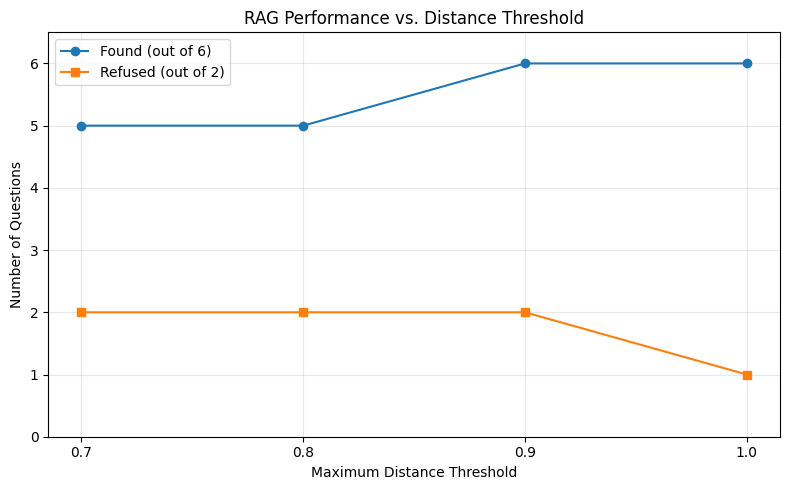

Created: figure.png


In [38]:
###################  YOUR CHART  ###################
# Draw at least one chart from your results and save it as a .png.
################

# Step 21: Create and save experiment chart

import pandas as pd
import matplotlib.pyplot as plt

# Load saved experiment results
df = pd.read_csv("/content/results.csv")

# Select distance threshold experiment
threshold_df = df[
    df["experiment"] == "distance_threshold"
]

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["max_distance"],
    threshold_df["found"],
    marker="o",
    label="Found (out of 6)"
)

plt.plot(
    threshold_df["max_distance"],
    threshold_df["refused"],
    marker="s",
    label="Refused (out of 2)"
)

plt.xlabel("Maximum Distance Threshold")
plt.ylabel("Number of Questions")
plt.title("RAG Performance vs. Distance Threshold")

plt.xticks([0.7, 0.8, 0.9, 1.0])
plt.yticks(range(0, 7))
plt.ylim(0, 6.5)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Save chart for submission
plt.savefig("/content/figure.png", dpi=300)

plt.show()

print("Created: figure.png")

In [39]:
# Step 22: Check whether retrieved chunks contain goldset evidence

import json
from pathlib import Path

goldset = json.loads(
    Path("/content/goldset.json").read_text(encoding="utf-8")
)

evidence_found = 0

for i, item in enumerate(goldset["questions"], start=1):

    if not item["answerable"]:
        continue

    hits = retrieve_password_info(
        item["question"],
        k=3,
        max_distance=0.9
    )

    # Combine retrieved chunks into one text
    retrieved_text = "\n".join(
        hit["text"] for hit in hits
    )

    # All listed evidence phrases must be present
    matched = all(
        phrase in retrieved_text
        for phrase in item["evidence"]
    )

    if matched:
        evidence_found += 1

    print(
        f"Q{i}: {'PASS' if matched else 'FAIL'} "
        f"| Retrieved chunks: {len(hits)}"
    )

print()
print("Evidence found:", evidence_found, "/ 6")

Q1: PASS | Retrieved chunks: 3
Q2: PASS | Retrieved chunks: 3
Q3: PASS | Retrieved chunks: 3
Q4: PASS | Retrieved chunks: 1
Q5: PASS | Retrieved chunks: 1
Q6: PASS | Retrieved chunks: 3

Evidence found: 6 / 6


---

## What to write up

The tables and charts above are the evidence. The report and the video are where you explain them.
See `MiniProject_RAG.md` for the full requirements. In short:

- Explain the complete RAG system in your own words: chunking, embeddings, the vector store, retrieval,
  augmentation, and generation, and where each one appears in your notebook.
- Describe the data you created and the questions you wrote, and why you chose the question your
  documents cannot answer.
- Report what your experiments showed: which setting changed your numbers most, what you would use, and
  whether anything found more answers while refusing less.
- Pick one question your RAG got wrong, look at the chunk it retrieved instead, and explain the mistake.

Submit one PDF report with the link to your GitHub project folder and the link to your video on its first
page. The notebook, `my_kb/`, `goldset.json`, `results.csv`, and your chart live in the repository, which
is private, with your instructor and the TA added as collaborators. The notebook must be committed with
its outputs showing.